# Olist: ML datasets for the two objectives

**Objectives covered**
1. **Delivery duration (regression)**: target `delivery_total_duration_days`
2. **Late delivery (classification)**: target `is_late` (1 = delivered after the estimated date)

**Steps, in the order given by the teacher**
1. Load
2. Join
3. Data cleaning (small check, the data is already clean)
4. Data transformation (encode `customer_state` and `seller_state`)
5. Feature engineering
6. Sanity checks
7. Dimension reduction (remove irrelevant columns, correlation matrix, PCA)
8. Data visualization
9. Save

**Before running:** upload the cleaned CSV files to the Colab file panel (`/content`), or mount Google Drive and change `DATA_DIR`.

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

DATA_DIR = '/content'
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    # save the current figure as a PNG with a clear name
    plt.savefig(f'{FIG_DIR}/{name}.png', dpi=150, bbox_inches='tight')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)

## 1. Load

In [ ]:
orders    = pd.read_csv(f'{DATA_DIR}/orders_master.csv',
                        parse_dates=['order_purchase_timestamp', 'order_delivered_customer_date'])
customers = pd.read_csv(f'{DATA_DIR}/olist_customers_clean.csv', dtype={'customer_zip_code_prefix': str})
payments  = pd.read_csv(f'{DATA_DIR}/order_payments_clean.csv')
items     = pd.read_csv(f'{DATA_DIR}/olist_order_items_agg.csv')
products  = pd.read_csv(f'{DATA_DIR}/olist_products_clean .csv')   # note the space in the file name
sellers   = pd.read_csv(f'{DATA_DIR}/clean_seller_0 (1).csv', dtype={'seller_zip_code_prefix': str})
geo       = pd.read_csv(f'{DATA_DIR}/olist_geolocation_clean.csv', dtype={'geolocation_zip_code_prefix': str})

for name, df in [('orders', orders), ('customers', customers), ('payments', payments),
                 ('items', items), ('products', products), ('sellers', sellers), ('geo', geo)]:
    print(f'{name:10s} {df.shape}')

orders     (98625, 30)
customers  (99441, 5)
payments   (99437, 15)
items      (98663, 14)
products   (32949, 12)
sellers    (3095, 4)
geo        (719743, 5)


## 2. Join

We start from the delivered orders and attach one table at a time:
customers, order items, products, payments, sellers and geolocation.

In [ ]:
# 2.1 Keep only delivered orders with a known duration and delay
base = orders[orders['is_delivered'] == 1].copy()
base = base.dropna(subset=['delivery_total_duration_days', 'delivery_delay_days',
                           'order_delivered_customer_date'])

base = base[['order_id', 'customer_id', 'order_purchase_timestamp', 'order_delivered_customer_date',
             'estimated_days', 'delivery_total_duration_days', 'delivery_delay_days']]
print('delivered orders:', len(base))

delivered orders: 95736


In [ ]:
# 2.2 Customers (state and zip prefix)
base = base.merge(customers[['customer_id', 'customer_state', 'customer_zip_code_prefix']],
                  on='customer_id', how='left')

In [ ]:
# 2.3 Order items (one row per order: number of items, sellers, prices, main product and seller)
items_cols = ['order_id', 'n_items', 'n_sellers', 'total_price', 'total_freight', 'freight_ratio',
              'main_product_id', 'main_seller_id', 'main_product_qty']
base = base.merge(items[items_cols], on='order_id', how='left')

In [ ]:
# 2.4 Products (English category name, weight and volume of the main product)
product_cols = ['product_id', 'product_weight_g', 'product_volume_cm3']
base = (base.merge(products[product_cols], left_on='main_product_id', right_on='product_id', how='left')
            .drop(columns='product_id'))

In [ ]:
# 2.5 Payments (one row per order)
pay_cols = ['order_id', 'total_paid', 'value_credit_card', 'value_boleto', 'value_voucher',
            'max_installments', 'n_payments', 'n_payment_types']
base = base.merge(payments[pay_cols], on='order_id', how='left')

In [ ]:
# 2.6 Sellers (state and zip prefix of the main seller)
base = base.merge(sellers[['seller_id', 'seller_state', 'seller_zip_code_prefix']],
                  left_on='main_seller_id', right_on='seller_id', how='left').drop(columns='seller_id')

# 2.7 Geolocation: one centroid (average latitude and longitude) per zip prefix
centroids = (geo.groupby('geolocation_zip_code_prefix', as_index=False)
                .agg(lat=('geolocation_lat', 'mean'), lng=('geolocation_lng', 'mean')))

# customer coordinates
base = base.merge(centroids.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                                            'lat': 'customer_lat', 'lng': 'customer_lng'}),
                  on='customer_zip_code_prefix', how='left')

# seller coordinates
base = base.merge(centroids.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
                                            'lat': 'seller_lat', 'lng': 'seller_lng'}),
                  on='seller_zip_code_prefix', how='left')

print('joined shape:', base.shape)

joined shape: (95736, 32)


## 3. Data cleaning (small check)

The data was already cleaned earlier, so this section only checks it:
duplicates, orders without a seller, missing values and impossible durations.

In [ ]:
# duplicates
print('duplicated order_id:', base['order_id'].duplicated().sum())
base = base.drop_duplicates(subset='order_id')

# an order with no items has no seller, so it cannot be used
print('orders without seller:', base['main_seller_id'].isna().sum())
base = base.dropna(subset=['main_seller_id'])

# durations must be positive
print('durations <= 0 days:', (base['delivery_total_duration_days'] <= 0).sum())

# missing values (kept for now, removed in the feature section)
missing = base.isna().sum()
print('\nmissing values per column:')
print(missing[missing > 0])

duplicated order_id: 0
orders without seller: 1
durations <= 0 days: 0

missing values per column:
product_weight_g       16
product_volume_cm3     16
customer_lat          264
customer_lng          264
seller_lat            212
seller_lng            212
dtype: int64


## 4. Data transformation: encode the states

`customer_state` and `seller_state` are text. We sort all states alphabetically,
give each one a number (0, 1, 2, ...) and replace the text with that number.
Both columns use **the same** mapping, so `CA` means the same number for customers and sellers.

In [ ]:
# all states that appear in customers or sellers, sorted alphabetically
states = sorted(set(base['customer_state'].dropna()) | set(base['seller_state'].dropna()))

state_numbers = {state: number for number, state in enumerate(states)}   # state -> number
state_names   = {number: state for state, number in state_numbers.items()} # number -> state

# replace the text with the numbers
base['customer_state'] = base['customer_state'].map(state_numbers)
base['seller_state']   = base['seller_state'].map(state_numbers)

# show the mapping
pd.DataFrame(list(state_numbers.items()), columns=['state', 'number']).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26
state,AC,AL,AM,AP,BA,CE,DF,ES,GO,MA,MG,MS,MT,PA,PB,PE,PI,PR,RJ,RN,RO,RR,RS,SC,SE,SP,TO
number,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26


## 5. Feature engineering

In [ ]:
# 5.1 Time features from the purchase date
base['purchase_month']   = base['order_purchase_timestamp'].dt.month
base['purchase_weekday'] = base['order_purchase_timestamp'].dt.weekday   # 0 = Monday
base['purchase_hour']    = base['order_purchase_timestamp'].dt.hour

In [ ]:
# 5.2 Distance between customer and seller (in km)
def haversine_km(lat1, lng1, lat2, lng2):
    # straight-line distance between two points on the Earth
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

base['distance_km'] = haversine_km(base['customer_lat'], base['customer_lng'],
                                   base['seller_lat'], base['seller_lng'])

# 5.3 Same state: 1 if the customer and the seller are in the same state
base['same_state'] = (base['customer_state'] == base['seller_state']).astype(int)

In [ ]:
# 5.4 Product size of the order (main product x quantity)
# note: only the main product is in the items file, so this can under-estimate big orders
base['total_weight_g']   = base['product_weight_g']   * base['main_product_qty']
base['total_volume_cm3'] = base['product_volume_cm3'] * base['main_product_qty']
base = base.drop(columns=['product_weight_g', 'product_volume_cm3'])

# 5.5 Payment shares: what part of the order was paid by card, boleto and voucher
total = base['total_paid'].replace(0, np.nan)
base['credit_card_share'] = (base['value_credit_card'] / total).fillna(0)
base['boleto_share']      = (base['value_boleto']      / total).fillna(0)
base['voucher_share']     = (base['value_voucher']     / total).fillna(0)
base = base.drop(columns=['value_credit_card', 'value_boleto', 'value_voucher'])

In [ ]:
# 5.6 Classification target: 1 = delivered after the estimated date
base['is_late'] = (base['delivery_delay_days'] > 0).astype(int)
print('late rate:', base['is_late'].mean().round(4))

late rate: 0.0816


In [ ]:
# 5.7 Seller history (classification only), using PAST orders only.
# For each order, the history is the seller's orders that were already DELIVERED
# before this order was PURCHASED. Their late label was known at that moment, so nothing leaks.
base = base.reset_index(drop=True)
past_n    = np.zeros(len(base), dtype=int)
past_late = np.zeros(len(base), dtype=int)

for seller, idx in base.groupby('main_seller_id').indices.items():
    group = base.iloc[idx]

    # this seller's orders sorted by delivery date
    order = np.argsort(group['order_delivered_customer_date'].values)
    delivered = group['order_delivered_customer_date'].values[order]
    cum_late = np.cumsum(group['is_late'].values[order])

    # how many of this seller's orders were delivered before each order was purchased?
    k = np.searchsorted(delivered, group['order_purchase_timestamp'].values, side='left')
    past_n[idx] = k
    past_late[idx] = np.where(k > 0, cum_late[np.maximum(k - 1, 0)], 0)

base['seller_past_n_orders']  = past_n
base['seller_past_late_rate'] = np.where(past_n > 0, past_late / np.maximum(past_n, 1), np.nan)

print('orders with no seller history:', (base['seller_past_n_orders'] == 0).sum())

orders with no seller history: 5365


In [ ]:
# 5.8 Feature list (model inputs)
feature_cols = [
    'estimated_days', 'purchase_month', 'purchase_weekday', 'purchase_hour',
    'customer_state', 'customer_zip_code_prefix', 'seller_state',
    'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'distance_km', 'same_state',
    'n_items', 'n_sellers', 'total_price', 'total_freight', 'freight_ratio',
    'total_weight_g', 'total_volume_cm3',
    'total_paid', 'max_installments', 'n_payments', 'n_payment_types',
    'credit_card_share', 'boleto_share', 'voucher_share',
]
seller_history_cols = ['seller_past_late_rate', 'seller_past_n_orders']

# 5.9 Remove rows with missing core values (about 0.5% of orders)
before = len(base)
base = base.dropna(subset=feature_cols + ['delivery_total_duration_days'])
print('rows dropped for missing values:', before - len(base))

# 5.10 Build the two datasets
df_reg = base[['order_id'] + feature_cols + ['delivery_total_duration_days']].copy()
df_clf = base[['order_id'] + feature_cols + seller_history_cols + ['is_late']].copy()

print('regression dataset:    ', df_reg.shape)
print('classification dataset:', df_clf.shape)

rows dropped for missing values: 491
regression dataset:     (95244, 29)
classification dataset: (95244, 31)


## 6. Sanity checks

Each row must be one order, and the key columns must be filled in
(seller history is allowed to be empty for a seller's first orders).

In [ ]:
for name, d in [('regression', df_reg), ('classification', df_clf)]:
    assert d['order_id'].is_unique, f'{name}: duplicated order_id'
    print(f'{name}: {d.shape[0]} rows, order_id is unique')

print('\nmissing values in regression data:', df_reg.isna().sum().sum())
print('late rate in classification data:', round(df_clf['is_late'].mean(), 4))

# both datasets must have the same rows in the same order (used later for plots)
assert (df_reg.index == df_clf.index).all()
df_reg['delivery_total_duration_days'].describe()

regression: 95244 rows, order_id is unique
classification: 95244 rows, order_id is unique

missing values in regression data: 0
late rate in classification data: 0.0815


,delivery_total_duration_days
count,95244.000000
mean,12.549595
std,9.538040
min,0.533414
25%,6.762017
50%,10.218542
75%,15.699329
max,209.628611


## 7. Dimension reduction

### 7.1 Remove irrelevant columns

- `customer_zip_code_prefix`: a zip code is a code, not a quantity.
- `customer_lat`, `customer_lng`, `seller_lat`, `seller_lng`: the raw coordinates are already summarised by `distance_km`.

Kept on purpose: `order_id` (to trace each row back to its order), `customer_state` and `seller_state` (encoded states, they describe where the order travels).

`main_category` was removed: it is text that neither model can use as it is. Encoding it would need your approval first.

In [ ]:
drop_cols = ['customer_zip_code_prefix',
             'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng']

df_reg = df_reg.drop(columns=drop_cols)
df_clf = df_clf.drop(columns=drop_cols)

print('regression columns:', df_reg.shape[1])
print('classification columns:', df_clf.shape[1])

regression columns: 24
classification columns: 26


### 7.2 Numeric columns for PCA

PCA needs numbers, so we use only the numeric features.
We leave out the target and the encoded state numbers (they are labels, not quantities).

In [ ]:
numeric_cols = [c for c in df_reg.columns
                if c not in ['customer_state', 'seller_state',
                             'delivery_total_duration_days']]
print(len(numeric_cols), 'numeric features:')
print(numeric_cols)

21 numeric features:
['order_id', 'estimated_days', 'purchase_month', 'purchase_weekday', 'purchase_hour', 'distance_km', 'same_state', 'n_items', 'n_sellers', 'total_price', 'total_freight', 'freight_ratio', 'total_weight_g', 'total_volume_cm3', 'total_paid', 'max_installments', 'n_payments', 'n_payment_types', 'credit_card_share', 'boleto_share', 'voucher_share']


### 7.3 Correlation matrix

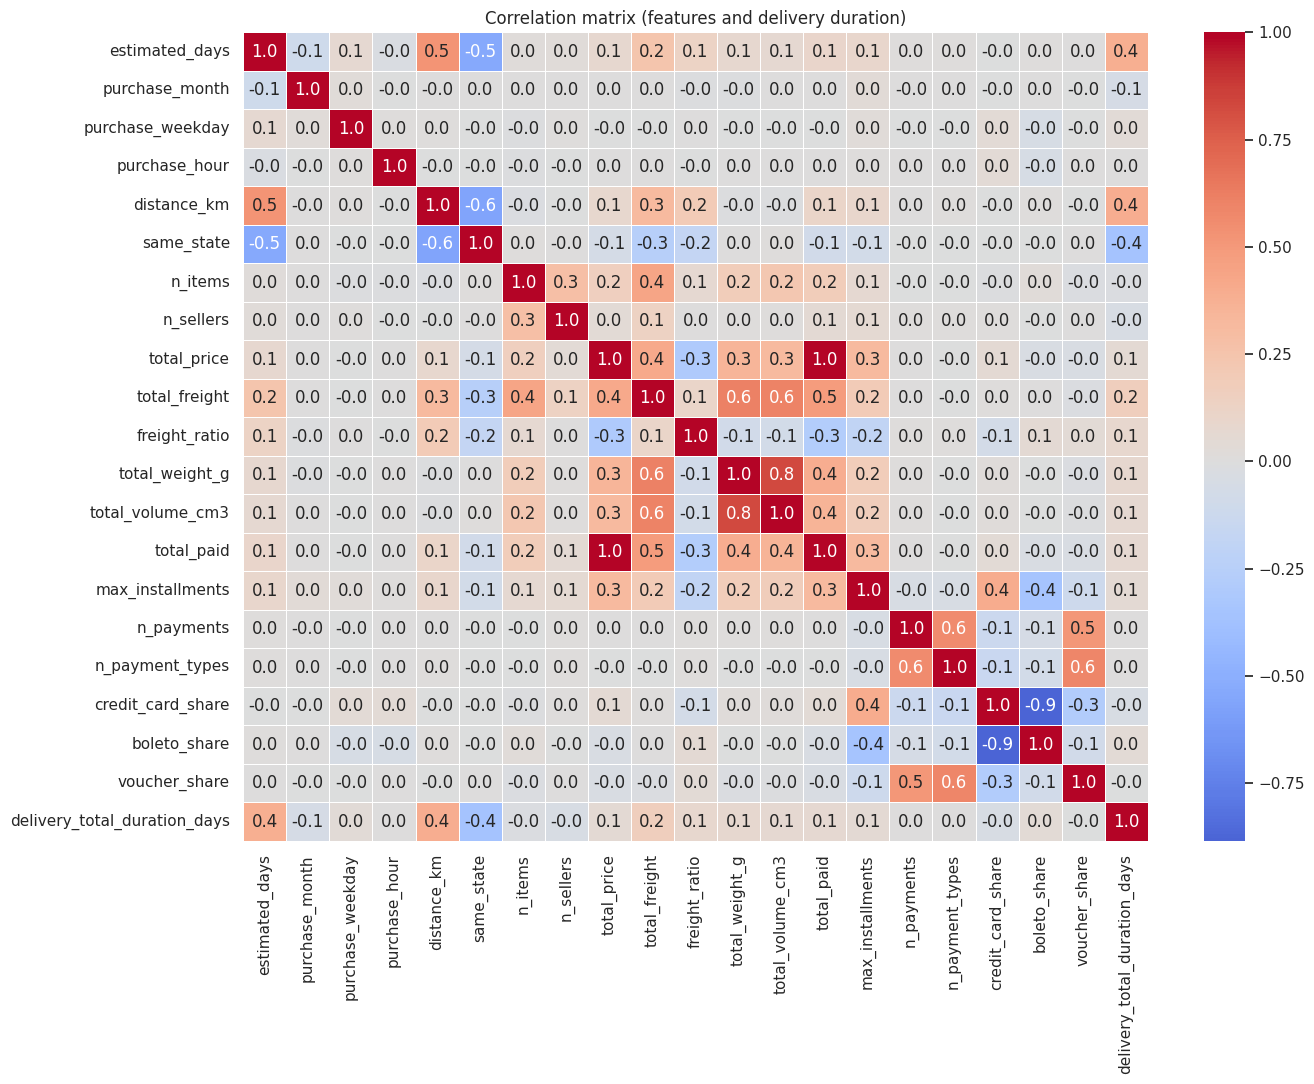

distance_km          0.395
estimated_days       0.385
same_state          -0.365
total_freight        0.167
freight_ratio        0.080
total_weight_g       0.075
total_paid           0.070
total_volume_cm3     0.067
purchase_month      -0.057
total_price          0.056
max_installments     0.052
boleto_share         0.050
n_sellers           -0.040
credit_card_share   -0.039
purchase_weekday     0.030
n_items             -0.019
n_payments           0.003
n_payment_types      0.002
purchase_hour        0.002
voucher_share       -0.002
Name: delivery_total_duration_days, dtype: float64


In [ ]:
# Exclude 'order_id' from the numeric columns as it contains string identifiers
plot_cols = [c for c in numeric_cols if c != 'order_id'] + ['delivery_total_duration_days']
corr = df_reg[plot_cols].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.1f', linewidths=0.4)
plt.title('Correlation matrix (features and delivery duration)')
plt.tight_layout()
save_fig('01_correlation_heatmap')
plt.show()

# which features move most with the delivery duration?
print(corr['delivery_total_duration_days'].drop('delivery_total_duration_days')
        .sort_values(key=abs, ascending=False).round(3))

Pairs with a correlation close to 1 (or -1) carry almost the same information.
For example, `total_paid` and `total_price + total_freight` are almost identical.
PCA will show how much of this redundancy there is.

### 7.4 PCA: how much information does each component keep?

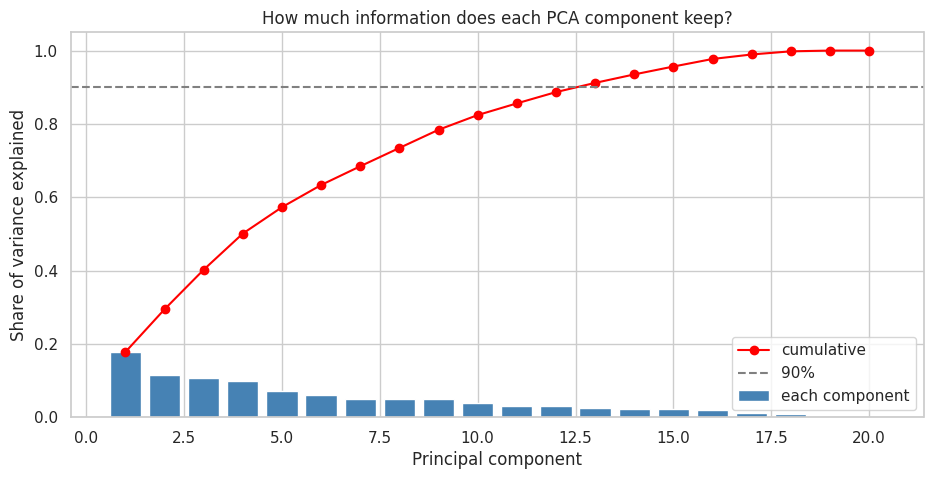

added PCA columns: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13']
13 components are needed to keep 90% of the information (out of 20)
first 2 components keep 29.4%


In [ ]:
# Exclude 'order_id' as it is a string identifier
pca_features = [c for c in numeric_cols if c != 'order_id']

# standardise first, so that features with large numbers (like prices) do not dominate
X = StandardScaler().fit_transform(df_reg[pca_features])

pca_full = PCA().fit(X)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(11, 5))
plt.bar(range(1, len(explained) + 1), explained, color='steelblue', label='each component')
plt.plot(range(1, len(explained) + 1), cumulative, color='red', marker='o', label='cumulative')
plt.axhline(0.90, color='gray', linestyle='--', label='90%')
plt.xlabel('Principal component')
plt.ylabel('Share of variance explained')
plt.title('How much information does each PCA component keep?')
plt.legend()
save_fig('02_pca_variance')
plt.show()

n_for_90 = int(np.argmax(cumulative >= 0.90)) + 1

# save the components that keep 90% of the information as new columns
pca_k = PCA(n_components=n_for_90)
pcs = pca_k.fit_transform(X)
pc_names = [f'PC{i + 1}' for i in range(n_for_90)]
df_reg = pd.concat([df_reg, pd.DataFrame(pcs, index=df_reg.index, columns=pc_names)], axis=1)
df_clf = pd.concat([df_clf, pd.DataFrame(pcs, index=df_clf.index, columns=pc_names)], axis=1)
print('added PCA columns:', pc_names)
print(f'{n_for_90} components are needed to keep 90% of the information (out of {len(explained)})')
print(f'first 2 components keep {cumulative[1]:.1%}')

### 7.5 PCA: 2D picture of the orders

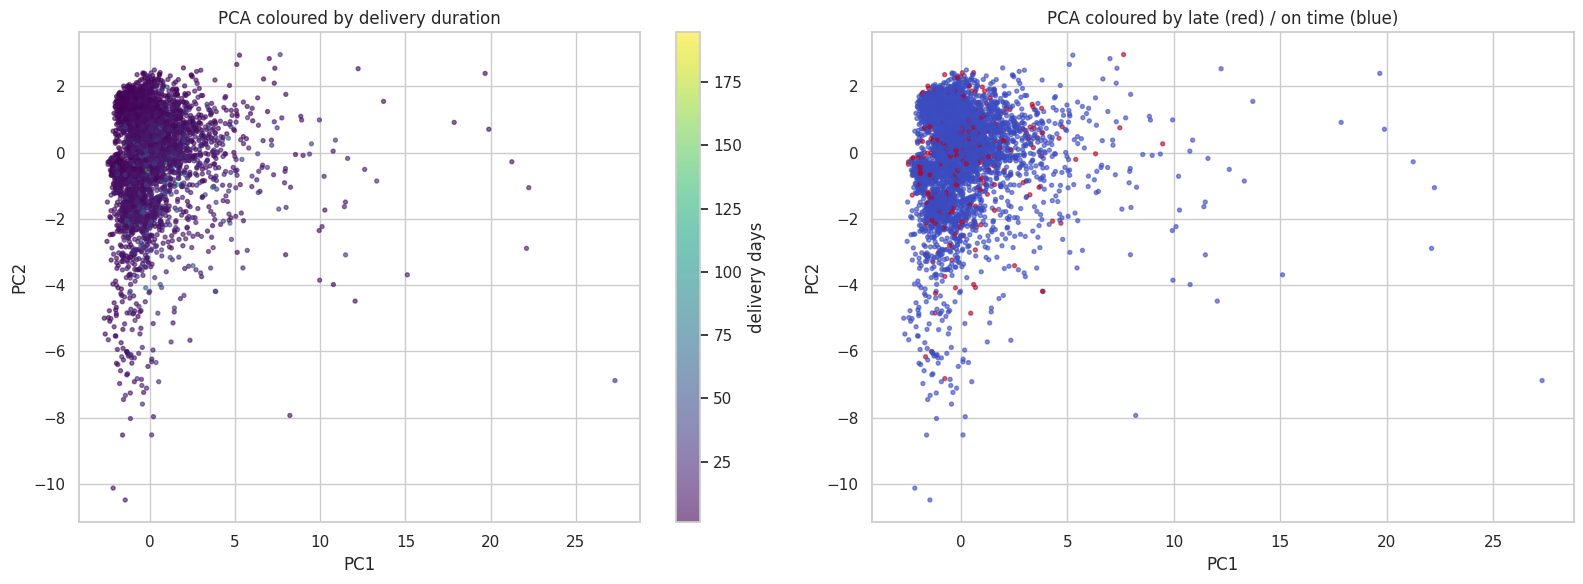

In [ ]:
pca2 = PCA(n_components=2)
X_2d = pca2.fit_transform(X)

# draw a random sample of 5000 orders so the plot stays readable
rng = np.random.default_rng(42)
sample = rng.choice(len(X_2d), size=min(5000, len(X_2d)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(X_2d[sample, 0], X_2d[sample, 1],
                     c=df_reg['delivery_total_duration_days'].values[sample],
                     cmap='viridis', s=8, alpha=0.6)
fig.colorbar(sc, ax=axes[0], label='delivery days')
axes[0].set_title('PCA coloured by delivery duration')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

late = df_clf['is_late'].values
axes[1].scatter(X_2d[sample, 0], X_2d[sample, 1], c=late[sample],
                cmap='coolwarm', s=8, alpha=0.6)
axes[1].set_title('PCA coloured by late (red) / on time (blue)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
save_fig('03_pca_scatter')
plt.show()

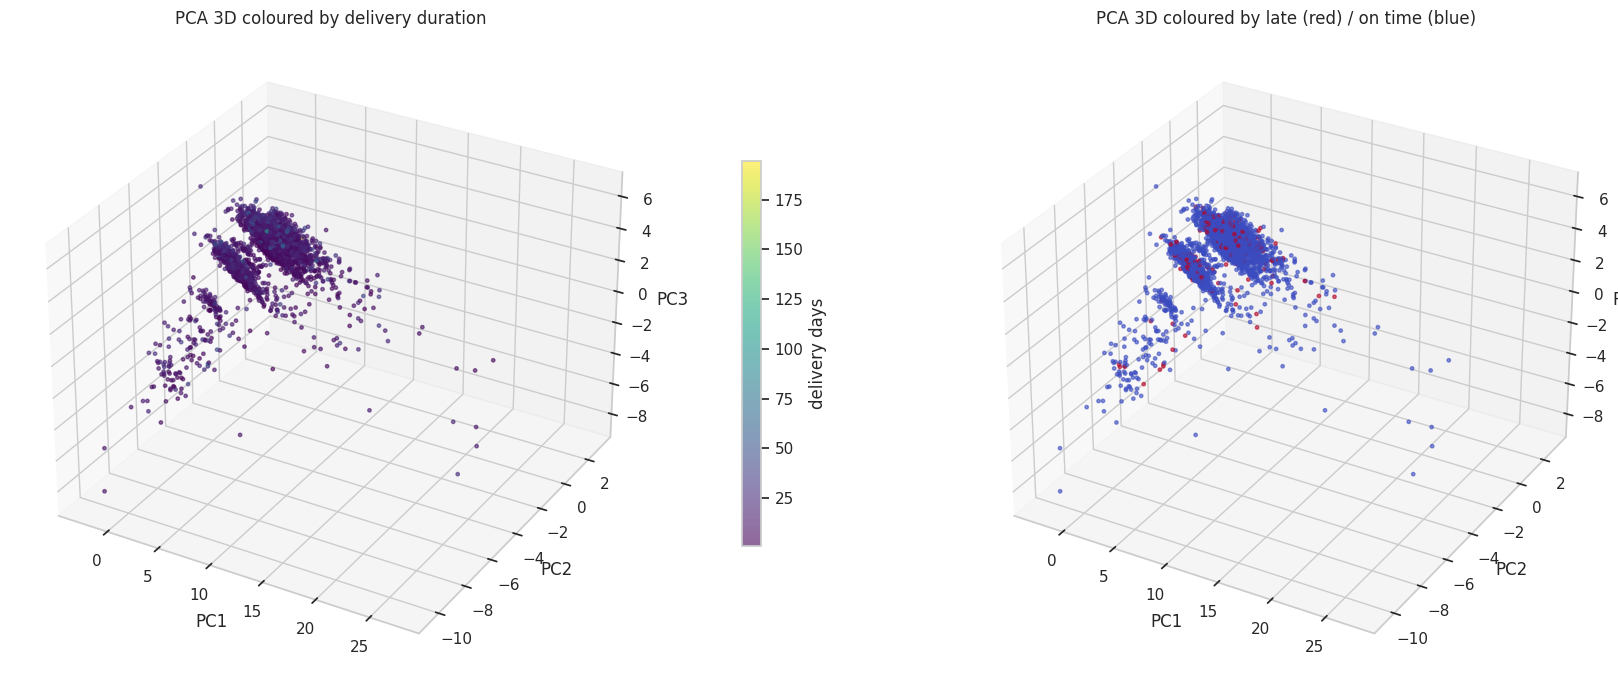

In [ ]:
pca3 = PCA(n_components=3)
X_3d = pca3.fit_transform(X)

# draw a random sample of 5000 orders so the plot stays readable
rng = np.random.default_rng(42)
sample = rng.choice(len(X_3d), size=min(5000, len(X_3d)), replace=False)

fig = plt.figure(figsize=(18, 7))

# left: coloured by delivery duration
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
sc = ax1.scatter(X_3d[sample, 0], X_3d[sample, 1], X_3d[sample, 2],
                 c=df_reg['delivery_total_duration_days'].values[sample],
                 cmap='viridis', s=6, alpha=0.6)
fig.colorbar(sc, ax=ax1, shrink=0.6, pad=0.1, label='delivery days')
ax1.set_title('PCA 3D coloured by delivery duration')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_zlabel('PC3')

# right: coloured by late (red) / on time (blue)
late = df_clf['is_late'].values
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.scatter(X_3d[sample, 0], X_3d[sample, 1], X_3d[sample, 2],
            c=late[sample], cmap='coolwarm', s=6, alpha=0.6)
ax2.set_title('PCA 3D coloured by late (red) / on time (blue)')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_zlabel('PC3')

plt.tight_layout()
save_fig('03_pca_scatter_3d')
plt.show()

### 7.6 What do the first two components mean?

In [ ]:
# the loadings show how much each feature contributes to PC1 and PC2
loadings = pd.DataFrame(pca2.components_.T, index=pca_features, columns=['PC1', 'PC2']).round(2)
loadings.sort_values('PC1', key=abs, ascending=False)

,PC1,PC2
total_paid,0.43,0.03
total_freight,0.42,-0.15
total_price,0.40,0.05
total_weight_g,0.38,-0.04
total_volume_cm3,0.37,-0.04
max_installments,0.25,0.24
n_items,0.20,-0.06
estimated_days,0.15,-0.24
distance_km,0.14,-0.25
same_state,-0.13,0.24


## 8. Data visualization

Simple plots that answer the business questions behind the two objectives.
Each figure is also saved as a PNG in the `figures/` folder.

### 8.1 Delivery duration

In [ ]:
# How long does a delivery take?
durations = df_reg['delivery_total_duration_days']

plt.figure(figsize=(10, 5))
plt.hist(durations.clip(upper=60), bins=60, color='steelblue', edgecolor='white')
plt.axvline(durations.mean(), color='red', linestyle='--', label=f'mean = {durations.mean():.1f} days')
plt.title('How long does a delivery take? (values above 60 days shown as 60)')
plt.xlabel('Delivery duration (days)')
plt.ylabel('Number of orders')
plt.legend()
save_fig('04_delivery_duration_histogram')
plt.show()

In [ ]:
# Average delivery time by customer state
avg_days = (df_reg.groupby(df_reg['customer_state'].map(state_names))['delivery_total_duration_days']
                  .mean().sort_values())

plt.figure(figsize=(13, 5))
avg_days.plot(kind='bar', color='steelblue')
plt.title('Average delivery time by customer state')
plt.xlabel('Customer state')
plt.ylabel('Average days')
plt.xticks(rotation=0)
save_fig('05_avg_delivery_by_state')
plt.show()

In [ ]:
# Does the distance between seller and customer matter? (sample of 5000 orders)
s = df_reg.sample(n=min(5000, len(df_reg)), random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(s['distance_km'], s['delivery_total_duration_days'], alpha=0.3, s=10, color='steelblue')
plt.title('Distance vs delivery duration')
plt.xlabel('Distance seller to customer (km)')
plt.ylabel('Delivery duration (days)')
save_fig('06_distance_vs_duration')
plt.show()

### 8.2 Late delivery

In [ ]:
# On time vs late
late_counts = df_clf['is_late'].value_counts().sort_index()
labels = ['On time', 'Late']

plt.figure(figsize=(6, 5))
bars = plt.bar(labels, late_counts.values, color=['seagreen', 'tomato'])
for bar, value in zip(bars, late_counts.values):
    share = value / late_counts.sum()
    plt.text(bar.get_x() + bar.get_width() / 2, value, f'{share:.1%}', ha='center', va='bottom')
plt.title('Share of late orders')
plt.ylabel('Number of orders')
save_fig('07_on_time_vs_late')
plt.show()

In [ ]:
# Late rate by customer state
late_by_state = (df_clf.groupby(df_clf['customer_state'].map(state_names))['is_late']
                       .mean().sort_values(ascending=False))

plt.figure(figsize=(13, 5))
late_by_state.plot(kind='bar', color='tomato')
plt.title('Share of late orders by customer state')
plt.xlabel('Customer state')
plt.ylabel('Share late')
plt.xticks(rotation=0)
save_fig('08_late_rate_by_state')
plt.show()

In [ ]:
# Late rate by purchase month
monthly_late = df_clf.groupby('purchase_month')['is_late'].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_late.index, monthly_late.values, marker='o', color='tomato')
plt.xticks(range(1, 13))
plt.title('Share of late orders by purchase month')
plt.xlabel('Purchase month')
plt.ylabel('Share late')
save_fig('09_late_rate_by_month')
plt.show()

## 9. Save

In [ ]:
df_reg.to_csv('dataset_regression.csv', index=False)
df_clf.to_csv('dataset_classification.csv', index=False)

print('saved dataset_regression.csv', df_reg.shape)
print('saved dataset_classification.csv', df_clf.shape)

try:
    from google.colab import files
    files.download('dataset_regression.csv')
    files.download('dataset_classification.csv')
except ImportError:
    pass

### PCA on the regression dataset

In [ ]:
# numeric features only: no state codes (labels), no target, no PC columns from earlier runs
reg_pca_cols = [c for c in df_reg.columns
                if c not in ['customer_state', 'seller_state', 'delivery_total_duration_days']
                and not c.startswith('PC')]

X_reg = StandardScaler().fit_transform(df_reg[reg_pca_cols])

pca_reg = PCA(n_components=3)
X_pca = pca_reg.fit_transform(X_reg)

print('variance explained by PC1, PC2, PC3:', pca_reg.explained_variance_ratio_.round(3))
print('total for 3 components:', pca_reg.explained_variance_ratio_.sum().round(3))

# which features drive each component
loadings_reg = pd.DataFrame(pca_reg.components_.T, index=reg_pca_cols,
                            columns=['PC1', 'PC2', 'PC3']).round(2)
loadings_reg.sort_values('PC1', key=abs, ascending=False)

###2D visualization (PC1 vs PC2)

In [ ]:
# random sample of 5000 orders so the plot stays readable
rng = np.random.default_rng(42)
sample = rng.choice(len(X_pca), size=min(5000, len(X_pca)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# left: coloured by delivery duration
sc = axes[0].scatter(X_pca[sample, 0], X_pca[sample, 1],
                     c=df_reg['delivery_total_duration_days'].values[sample],
                     cmap='viridis', s=8, alpha=0.6)
fig.colorbar(sc, ax=axes[0], label='delivery days')
axes[0].set_title('Regression PCA (2D) coloured by delivery duration')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

# right: coloured by distance between seller and customer
sc2 = axes[1].scatter(X_pca[sample, 0], X_pca[sample, 1],
                      c=df_reg['distance_km'].values[sample],
                      cmap='plasma', s=8, alpha=0.6)
fig.colorbar(sc2, ax=axes[1], label='distance (km)')
axes[1].set_title('Regression PCA (2D) coloured by distance')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
save_fig('03_reg_pca_2d')
plt.show()

###3D visualization (PC1, PC2, PC3)

In [ ]:
fig = plt.figure(figsize=(18, 7))

# left: coloured by delivery duration
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
sc = ax1.scatter(X_pca[sample, 0], X_pca[sample, 1], X_pca[sample, 2],
                 c=df_reg['delivery_total_duration_days'].values[sample],
                 cmap='viridis', s=6, alpha=0.6)
fig.colorbar(sc, ax=ax1, shrink=0.6, pad=0.1, label='delivery days')
ax1.set_title('Regression PCA (3D) coloured by delivery duration')
ax1.set_xlabel('PC1')
ax1.set_ylabel('PC2')
ax1.set_zlabel('PC3')

# right: coloured by distance
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
sc2 = ax2.scatter(X_pca[sample, 0], X_pca[sample, 1], X_pca[sample, 2],
                  c=df_reg['distance_km'].values[sample],
                  cmap='plasma', s=6, alpha=0.6)
fig.colorbar(sc2, ax=ax2, shrink=0.6, pad=0.1, label='distance (km)')
ax2.set_title('Regression PCA (3D) coloured by distance')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.set_zlabel('PC3')

plt.tight_layout()
save_fig('03_reg_pca_3d')
plt.show()